# Renewable LCOE Sensitivity: Low / Medium / High

This model currently prices renewables (`src.assumptions.Renewables.LCOE` /
`ModelImpliedLCOE`) using only DESNZ Electricity Generation Costs 2025's
**Medium** cost & hurdle-rate scenario (`src/lcoe.py`'s
`renewables_2050_lcoe(technology)` defaults to `hurdle_rate_scenario="Medium"`,
and `src/assumptions.py` never overrides it). Annex A also publishes **Low**
and **High** scenarios for pre-development cost, construction cost,
infrastructure cost, hurdle rate and decommissioning cost.

This notebook makes that Low/Medium/High spread visible:

- **Part A** -- total LCOE and its cost-component breakdown for the three
  technologies wired into the model (`Large Scale Solar PV`, `Onshore Wind`,
  `Fixed Offshore Wind`), 2050 commissioning, across all three scenarios,
  using the `era5_2024` potential capacity factor (the same source
  `PowerSystem` and the rest of `nbs/` use by default), derated by a
  representative curtailment fraction (see the "Representative curtailment
  scenario" section right after the imports below).
- **Part B** -- reference-plant (DESNZ) load factor vs this model's own
  era5_2024-derived, curtailment-adjusted capacity factor (Part A's basis),
  across all three scenarios.
- **Part C** -- three-way comparison of reference-plant (DESNZ), Ninja 2025
  (curtailment-adjusted) and era5_2024 (curtailment-adjusted, Newbery 2025's
  "LACoE") LCOE, across all three scenarios. Each curtailment-adjusted source
  is derated by the curtailment fraction of **its own** `PowerSystem`
  simulation (its own weather series; both simulated at the same installed
  capacity), not a shared one -- see the "Representative curtailment scenario"
  section below.
- **Part D** -- broadens beyond the 3 core 2050 technologies to the fuller
  Annex A set (adds Tidal Stream Energy and Deep Granite Geothermal) across
  all five commissioning years (2030-2050), still across Low/Medium/High.
- **Part E** -- a literature-informed Low/Medium/High for E-DAC's
  equipment-only LCOR (CAPEX + fixed OPEX), built by varying the 2050 global
  DAC deployment assumption and the discount-rate scenario.

**Note on scope**: "Low/Medium/High" here is DESNZ's *cost & hurdle-rate*
scenario axis, not a weather/demand scenario -- it answers "how sensitive is
the £/MWh figure to Annex A's own uncertainty range", not "what if the
weather is different".

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Make `src` importable whether the notebook is run from the repo root or from `nbs/`.
_root = Path.cwd().resolve()
while _root != _root.parent and not (_root / "src").exists():
    _root = _root.parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))
OUTPUT_DIR = _root / "nbs" / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PDF_OUTPUT_DIR = _root / "output" / "pdf"
PDF_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import src.assumptions as A
import src.matplotlib_style  # noqa: F401
from src.curtailment_lcoe import average_curtailment_adjusted_lcoe
from src.data.annex_a_lcoe import load_technical_assumptions
from src.lcoe import RENEWABLES_2050_PARAMS, calculate_lcoe, renewables_2050_lcoe
from src.units import Units as U

SCENARIOS = ["Low", "Medium", "High"]
CORE_TECHNOLOGIES = list(RENEWABLES_2050_PARAMS.keys())
SCENARIO_COLORS = {"Low": "tab:green", "Medium": "tab:blue", "High": "tab:red"}
COST_COMPONENTS = ["pre_development", "construction", "fixed_om", "variable_om", "fuel"]

# The older, static "Renewables.ninja"-derived capacity factors (see
# src.assumptions.Renewables.CapacityFactors's docstring). Part C's "Ninja 2025"
# column no longer uses these -- it runs the newer ninja_2025 dataset through its
# own simulation -- so they are kept only for the capacity-factor comparison table,
# to show how far these legacy constants sit from the live series.
MODEL_CAPACITY_FACTOR = {
    "Large Scale Solar PV": A.Renewables.CapacityFactors.Solar,
    "Fixed Offshore Wind": A.Renewables.CapacityFactors.OffshoreWind,
    "Onshore Wind": A.Renewables.CapacityFactors.OnshoreWind,
}

CORE_TECHNOLOGIES

['Large Scale Solar PV', 'Onshore Wind', 'Fixed Offshore Wind']

## Representative curtailment scenario

Runs a representative `PowerSystem` simulation **per capacity-factor source**
to get a real, model-simulated curtailed-energy figure from that source's own
weather series, rather than the full multi-hundred-GW optimisation scan
`Best_senario.ipynb` runs to find a cost-minimising capacity. These are
representative points, not re-optimised "best" scenarios. Both simulations
use the same ERA5 demand series (1979-2019), 2 GW DAC and hydrogen-storage
configuration; each runs over the weather years its source shares with that
demand (~41 years), not a single year.

Both simulations use **one shared installed capacity, `REN_GW = 260`**, so the
Ninja 2025-vs-era5_2024 comparison in Part C reflects the weather series
rather than system size. 260 GW is the smallest capacity on the 10 GW grid
(the same grid as `src.supply_model.get_net_supply`) at which *both* weather
series can meet demand: `ninja_2025`'s offshore wind capacity factor (~0.45)
is well below `era5_2024`'s (~0.64), so under Ninja 2025 weather the
simulation fails (storage exhausted) at 250 GW and below, whereas `era5_2024`
already works at 200 GW. Note that this makes the `era5_2024` curtailment
higher than it would be at a smaller, era5-only representative size (200 GW
gave 9.3%), which feeds through to Parts A, B and E.

- **era5_2024** -- also extracts the `era5_2024` potential and
  curtailment-derated capacity factors (`ERA5_POTENTIAL_CF` /
  `ERA5_CURTAILED_CF`). `era5_2024` is the capacity-factor source used by
  `PowerSystem`'s own default and by every other notebook in `nbs/` that runs
  a simulation, so **Parts A, B and E** use this simulation.
- **Ninja 2025 (`ninja_2025`)** -- the Renewables.ninja 2025 dataset (future
  onshore / offshore fleets, 1980-2024), used only in **Part C**. (The older
  `renewable_ninja` dataset, whose means equal the static
  `Renewables.CapacityFactors` constants, has an even lower offshore capacity
  factor of ~0.38 and needed 340 GW; it is no longer used here.)

**Part C** keeps both the Ninja 2025 and era5_2024 curtailment-adjusted
figures side by side, alongside the DESNZ reference-plant figure, so the two
capacity-factor sources stay directly comparable.

The curtailment fraction itself is a *dispatch* outcome -- fixed once the
simulation has run, independent of cost scenario -- and is applied pro-rata
across all three technologies (matching Newbery (2025)'s pro-rata-curtailment
case; see `src.curtailment_lcoe`'s module docstring).

*Minor known nuance*: `src.curtailment_lcoe` takes each technology's potential
capacity factor as the mean over the source's **full** data range, whereas the
simulation only covers the years the source shares with the demand series
(e.g. era5_2024 offshore wind: 0.636 full-range vs 0.643 over the shared
years, ~1%). Not changed here.

In [2]:
from src.data import renewable_capacity_factors
from src.demand_model import DemandMode, predicted_demand
from src.power_system import PowerSystem
from src.supply_model import daily_renewables_capacity

DAC_GW = 2
# One installed capacity shared by both sources. 260 GW is the smallest capacity on the 10 GW grid
# (src.supply_model.get_net_supply's range(100, 500, 10)) at which BOTH weather series can meet demand:
# ninja_2025's offshore wind is weaker (~0.45 vs ~0.64 capacity factor), so it exhausts storage at 250 GW and below.
REN_GW = 260
CAPACITY_FACTORS_SOURCE = "era5_2024"
NINJA_SOURCE = "ninja_2025"  # Renewables.ninja 2025 dataset (future onshore / offshore fleets), 1980-2024

demand_df = predicted_demand(mode=DemandMode.SEASONAL, historical="era5", filter_ldz=True)


def run_representative_simulation(source: str, ren_gw: int) -> dict | None:
    """Run one PowerSystem simulation driven by ``source``'s own weather series.

    Returns None if the simulation fails (storage exhausted), i.e. ``ren_gw`` cannot meet demand under
    this weather. Otherwise returns the curtailed energy, the curtailment fraction and the
    potential / curtailment-derated capacity factors -- all derived from the same ``source``.
    """
    daily_cf = renewable_capacity_factors.get_renewable_capacity_factors(source=source, resample="D")
    supply = daily_renewables_capacity(ren_gw * U.GW, daily_cf)
    common_idx = supply.index.intersection(demand_df.index)
    net_supply_df = (supply.reindex(common_idx) - demand_df["demand"].reindex(common_idx)).to_frame(name=f"S-D(TWh),Ren={ren_gw}GW")

    power_system = PowerSystem(
        renewable_capacity=ren_gw * U.GW,
        hydrogen_storage_capacity=A.HydrogenStorage.CavernStorage.Capacity,
        electrolyser_power=A.HydrogenStorage.Electrolysis.Power,
        dac_capacity=DAC_GW * U.GW,
        capacity_factors_source=source,
    )
    sim_df = power_system.run_simulation(net_supply_df)
    if sim_df is None:
        return None
    simulation_results = power_system.analyze_simulation_results(sim_df)
    curtailed_energy = simulation_results["curtailed_energy"].to(U.TWh)

    # curtailment_fraction and the potential/curtailment-derated capacity factors are all
    # scenario-independent (see src.curtailment_lcoe.average_curtailment_adjusted_lcoe) --
    # "Medium" here is an arbitrary choice just to extract them once, ahead of Part A.
    result = average_curtailment_adjusted_lcoe(
        ren_gw * U.GW, curtailed_energy, capacity_factors_source=source, hurdle_rate_scenario="Medium"
    )
    return {
        "simulation_results": simulation_results,
        "curtailed_energy": curtailed_energy,
        "curtailment_fraction": result["curtailment_fraction"],
        "potential_cf": result["potential_capacity_factor"],
        "curtailed_cf": result["average_capacity_factor"],
    }


# --- era5_2024 (Parts A, B and E all use these names) ---
era5_run = run_representative_simulation(CAPACITY_FACTORS_SOURCE, REN_GW)
assert era5_run is not None, "era5_2024 simulation failed (storage exhausted) -- adjust REN_GW/DAC_GW"
simulation_results = era5_run["simulation_results"]
curtailed_energy = era5_run["curtailed_energy"]
curtailment_fraction = era5_run["curtailment_fraction"]
ERA5_POTENTIAL_CF = era5_run["potential_cf"]
ERA5_CURTAILED_CF = era5_run["curtailed_cf"]

# --- Ninja 2025: same capacity / demand / DAC / storage configuration, but driven by ninja_2025's own weather ---
ninja_run = run_representative_simulation(NINJA_SOURCE, REN_GW)
assert ninja_run is not None, "Ninja 2025 simulation failed (storage exhausted) -- raise REN_GW"
ninja_curtailed_energy = ninja_run["curtailed_energy"]
NINJA_CURTAILMENT_FRACTION = ninja_run["curtailment_fraction"]
NINJA_POTENTIAL_CF = ninja_run["potential_cf"]
NINJA_CURTAILED_CF = ninja_run["curtailed_cf"]

print(f"Both simulations: renewable_capacity={REN_GW} GW, dac_capacity={DAC_GW} GW")
print(f"era5_2024: simulated curtailed energy {curtailed_energy:.1f}")
print(f"  Curtailment fraction (dispatch outcome, pro-rata across technologies): {curtailment_fraction:.1%}")
print(f"Ninja 2025: simulated curtailed energy {ninja_curtailed_energy:.1f}")
print(f"  Curtailment fraction (dispatch outcome, pro-rata across technologies): {NINJA_CURTAILMENT_FRACTION:.1%}")

Both simulations: renewable_capacity=260 GW, dac_capacity=2 GW
era5_2024: simulated curtailed energy 246.4 terawatt_hour
  Curtailment fraction (dispatch outcome, pro-rata across technologies): 29.0%
Ninja 2025: simulated curtailed energy 67.1 terawatt_hour
  Curtailment fraction (dispatch outcome, pro-rata across technologies): 10.0%


## Part A -- Core 2050 curtailment-adjusted LCOE (era5_2024), Low / Medium / High

Uses each technology's `era5_2024` potential capacity factor (`ERA5_POTENTIAL_CF`,
the same live weather series that drives this model's `PowerSystem`
simulations elsewhere in the repo), derated by the representative curtailment
fraction computed above -- instead of DESNZ's reference-plant load factor, and
instead of the older static `Renewables.CapacityFactors` ("Ninja") constants
that Part B still uses. Only cost and hurdle-rate assumptions vary across
Low/Medium/High.

In [3]:
def lcoe_breakdown_row(technology: str, scenario: str, breakdown: dict) -> dict:
    row = {"technology": technology, "scenario": scenario}
    for component in [*COST_COMPONENTS, "total"]:
        row[component] = breakdown[component].to(U.GBP / U.MWh).magnitude
    return row


rows_a = []
for technology in CORE_TECHNOLOGIES:
    for scenario in SCENARIOS:
        breakdown = renewables_2050_lcoe(technology, scenario, load_factor=ERA5_CURTAILED_CF[technology])
        rows_a.append(lcoe_breakdown_row(technology, scenario, breakdown))

lcoe_a = pd.DataFrame(rows_a)
display(lcoe_a.round(2))

,technology,scenario,pre_development,construction,fixed_om,variable_om,fuel,total
0,Large Scale Solar PV,Low,1.13,41.85,12.32,0.0,0.0,55.30
1,Large Scale Solar PV,Medium,4.22,62.19,12.32,0.0,0.0,78.72
2,Large Scale Solar PV,High,11.73,78.72,12.32,0.0,0.0,102.77
3,Onshore Wind,Low,2.01,47.63,20.54,0.0,0.0,70.18
4,Onshore Wind,Medium,5.60,68.84,20.54,0.0,0.0,94.98
5,Onshore Wind,High,27.26,116.47,20.54,0.0,0.0,164.27
6,Fixed Offshore Wind,Low,2.65,41.46,33.96,0.0,0.0,78.07
7,Fixed Offshore Wind,Medium,5.62,58.59,33.96,0.0,0.0,98.17
8,Fixed Offshore Wind,High,25.90,99.45,33.96,0.0,0.0,159.31


C:\Users\Yutong Ren\AppData\Local\Temp\ipykernel_23160\366091467.py:14: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


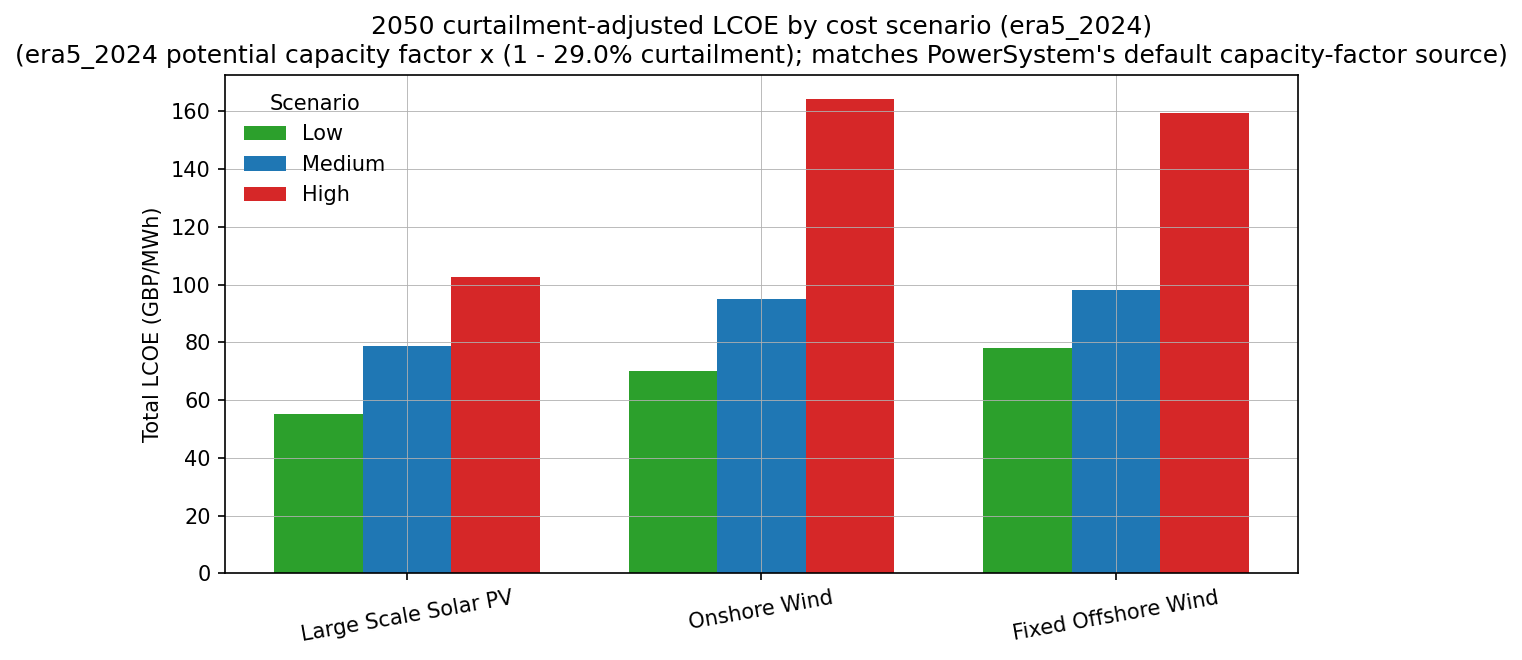

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(CORE_TECHNOLOGIES))
width = 0.25

for i, scenario in enumerate(SCENARIOS):
    totals = [lcoe_a.query("technology == @tech and scenario == @scenario")["total"].iloc[0] for tech in CORE_TECHNOLOGIES]
    ax.bar(x + (i - 1) * width, totals, width, label=scenario, color=SCENARIO_COLORS[scenario])

ax.set_xticks(x)
ax.set_xticklabels(CORE_TECHNOLOGIES, rotation=10)
ax.set_ylabel("Total LCOE (GBP/MWh)")
ax.set_title(f"2050 curtailment-adjusted LCOE by cost scenario (era5_2024)\n(era5_2024 potential capacity factor x (1 - {curtailment_fraction:.1%} curtailment); matches PowerSystem's default capacity-factor source)")
ax.legend(title="Scenario", frameon=False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "renewable_lcoe_sensitivity_part_a_totals.png", dpi=150, bbox_inches="tight")
plt.show()

C:\Users\Yutong Ren\AppData\Local\Temp\ipykernel_23160\2144344523.py:17: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


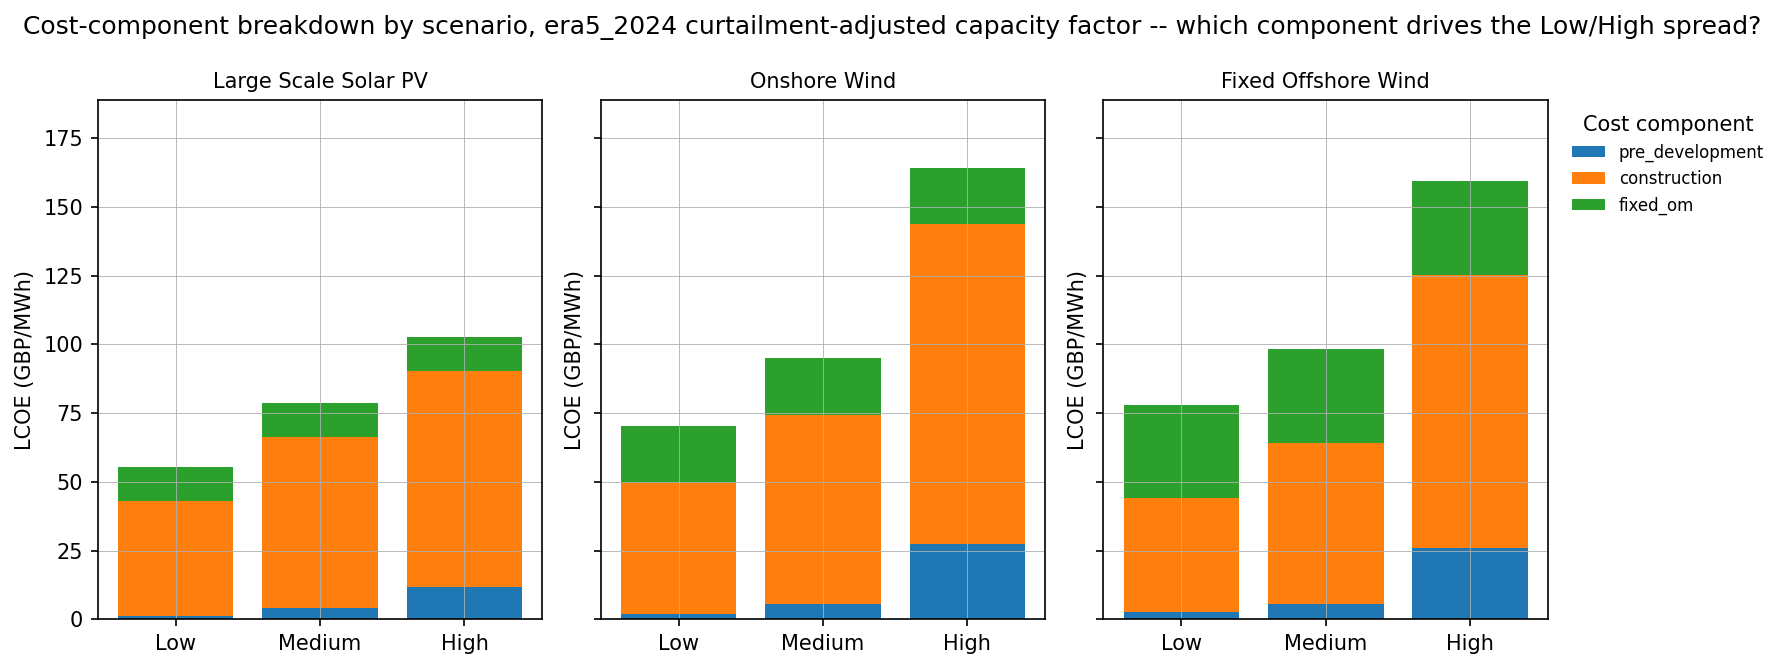

In [5]:
chart_components = [c for c in COST_COMPONENTS if lcoe_a[c].max() > 0]  # drop always-zero components (e.g. variable_om, fuel) from the legend

fig, axes = plt.subplots(1, len(CORE_TECHNOLOGIES), figsize=(4 * len(CORE_TECHNOLOGIES), 4.5), sharey=True)

for ax, technology in zip(axes, CORE_TECHNOLOGIES, strict=False):
    bottoms = np.zeros(len(SCENARIOS))
    for component in chart_components:
        values = [lcoe_a.query("technology == @technology and scenario == @scenario")[component].iloc[0] for scenario in SCENARIOS]
        ax.bar(SCENARIOS, values, bottom=bottoms, label=component)
        bottoms += np.array(values)
    ax.set_title(technology, fontsize=10)
    ax.set_ylabel("LCOE (GBP/MWh)")

axes[0].set_ylim(0, lcoe_a["total"].max() * 1.15)
axes[-1].legend(title="Cost component", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=8)
fig.suptitle("Cost-component breakdown by scenario, era5_2024 curtailment-adjusted capacity factor -- which component drives the Low/High spread?")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "renewable_lcoe_sensitivity_part_a_breakdown.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
breakdown_table = lcoe_a.set_index(["technology", "scenario"]).loc[
    [(tech, scenario) for tech in CORE_TECHNOLOGIES for scenario in SCENARIOS],
    [*chart_components, "total"],
]
display(breakdown_table.round(2))

pre_development  construction  fixed_om   total
technology           scenario                                                 
Large Scale Solar PV Low                  1.13         41.85     12.32   55.30
                     Medium               4.22         62.19     12.32   78.72
                     High                11.73         78.72     12.32  102.77
Onshore Wind         Low                  2.01         47.63     20.54   70.18
                     Medium               5.60         68.84     20.54   94.98
                     High                27.26        116.47     20.54  164.27
Fixed Offshore Wind  Low                  2.65         41.46     33.96   78.07
                     Medium               5.62         58.59     33.96   98.17
                     High                25.90         99.45     33.96  159.31

## Part B -- Reference-plant vs era5_2024 curtailment-adjusted capacity factor

Compares DESNZ's reference-plant load factor against this model's own
era5_2024-derived, curtailment-adjusted capacity factor (`ERA5_CURTAILED_CF`,
the same basis as Part A), across all three scenarios.

In [7]:
rows_b = []
for technology in CORE_TECHNOLOGIES:
    for scenario in SCENARIOS:
        reference_total = renewables_2050_lcoe(technology, scenario)["total"].to(U.GBP / U.MWh).magnitude
        era5_total = renewables_2050_lcoe(technology, scenario, load_factor=ERA5_CURTAILED_CF[technology])["total"].to(U.GBP / U.MWh).magnitude
        rows_b.append({
            "technology": technology,
            "scenario": scenario,
            "reference_plant_total": reference_total,
            "era5_curtailment_adjusted_total": era5_total,
        })

lcoe_b = pd.DataFrame(rows_b)
display(lcoe_b.round(2))

,technology,scenario,reference_plant_total,era5_curtailment_adjusted_total
0,Large Scale Solar PV,Low,35.45,55.30
1,Large Scale Solar PV,Medium,50.46,78.72
2,Large Scale Solar PV,High,65.88,102.77
3,Onshore Wind,Low,38.26,70.18
4,Onshore Wind,Medium,51.78,94.98
5,Onshore Wind,High,89.55,164.27
6,Fixed Offshore Wind,Low,70.49,78.07
7,Fixed Offshore Wind,Medium,88.64,98.17
8,Fixed Offshore Wind,High,143.85,159.31


C:\Users\Yutong Ren\AppData\Local\Temp\ipykernel_23160\3251127125.py:16: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


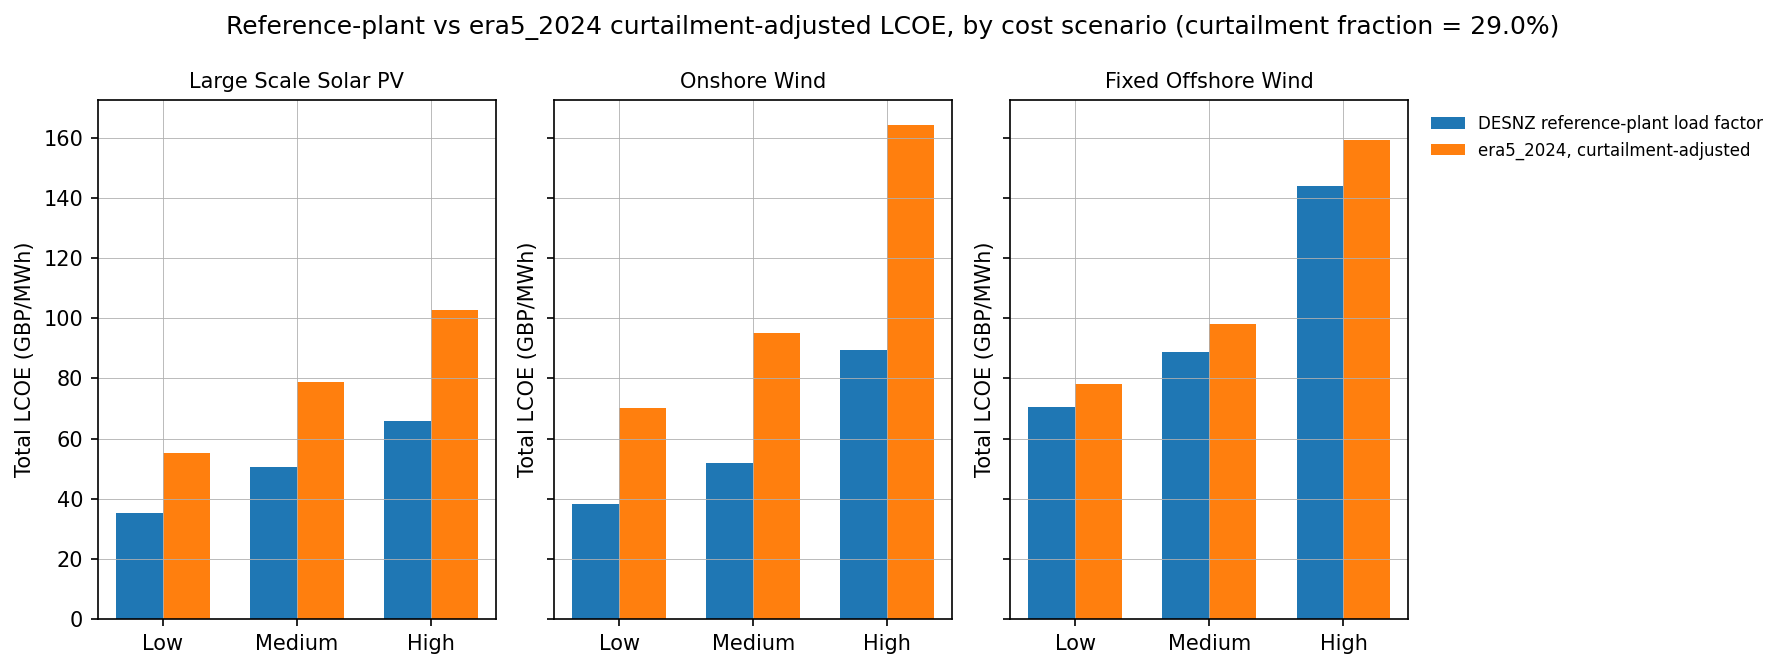

In [8]:
fig, axes = plt.subplots(1, len(CORE_TECHNOLOGIES), figsize=(4 * len(CORE_TECHNOLOGIES), 4.5), sharey=True)
x = np.arange(len(SCENARIOS))
width = 0.35

for ax, technology in zip(axes, CORE_TECHNOLOGIES, strict=False):
    subset = lcoe_b[lcoe_b["technology"] == technology].set_index("scenario").loc[SCENARIOS]
    ax.bar(x - width / 2, subset["reference_plant_total"], width, label="DESNZ reference-plant load factor")
    ax.bar(x + width / 2, subset["era5_curtailment_adjusted_total"], width, label="era5_2024, curtailment-adjusted")
    ax.set_xticks(x)
    ax.set_xticklabels(SCENARIOS)
    ax.set_title(technology, fontsize=10)
    ax.set_ylabel("Total LCOE (GBP/MWh)")

axes[-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=8)
fig.suptitle(f"Reference-plant vs era5_2024 curtailment-adjusted LCOE, by cost scenario (curtailment fraction = {curtailment_fraction:.1%})")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "renewable_lcoe_sensitivity_part_b.png", dpi=150, bbox_inches="tight")
plt.show()

## Part C -- DESNZ vs Ninja 2025 vs ERA5 2024, Low / Medium / High

Compares three renewable LCOE bases side by side. The two curtailment-adjusted
bases (Ninja 2025 and ERA5 2024) each use the curtailment fraction from
**their own** representative `PowerSystem` simulation (see the
"Representative curtailment scenario" section above):

- **DESNZ** -- the unmodified DESNZ Annex A reference-plant load factor
  (same as Part B's `reference_plant_total`); not curtailment-adjusted, since
  DESNZ's own load factor is a theoretical plant-level figure, not tied to
  any particular grid-scale deployment.
- **Ninja 2025** -- the Renewables.ninja 2025 weather series (`ninja_2025`),
  run through its own simulation (at the same installed capacity as
  ERA5 2024) and derated by that simulation's curtailment fraction, via
  `average_curtailment_adjusted_lcoe(..., capacity_factors_source="ninja_2025")`.
- **ERA5 2024** -- Newbery (2025)'s "LACoE" via
  `src.curtailment_lcoe.average_curtailment_adjusted_lcoe`, using the
  `era5_2024` live potential capacity factor (Part A and Part B's basis)
  derated by the ERA5 2024 simulation's curtailment fraction.

Seeing Ninja 2025 and ERA5 2024 side by side (rather than just picking one)
makes the underlying capacity-factor discrepancy between the two data sources
visible directly in the LCOE numbers, rather than hiding it -- see the note
below on offshore wind.

In [9]:
CAPACITY_RATIOS = {
    "Large Scale Solar PV": A.Renewables.CapacityRatios.Solar,
    "Fixed Offshore Wind": A.Renewables.CapacityRatios.OffshoreWind,
    "Onshore Wind": A.Renewables.CapacityRatios.OnshoreWind,
}
RENEWABLE_REFERENCE_LOAD_FACTOR = {
    technology: RENEWABLES_2050_PARAMS[technology]["Average load factor (net load factor)"] for technology in CORE_TECHNOLOGIES
}


def portfolio_weighted_total(totals_by_tech: dict, potential_cf_by_tech: dict) -> float:
    """Generation-share-weighted portfolio total (weight = capacity ratio x potential capacity factor).

    Matches how average_curtailment_adjusted_lcoe weights its own portfolio_lacoe.
    """
    generation_share = {technology: CAPACITY_RATIOS[technology] * potential_cf_by_tech[technology] for technology in CORE_TECHNOLOGIES}
    total_share = sum(generation_share.values())
    return sum(totals_by_tech[technology] * generation_share[technology] / total_share for technology in CORE_TECHNOLOGIES)


def lacoe_totals(result: dict) -> dict:
    """Per-technology LACoE in GBP/MWh from an average_curtailment_adjusted_lcoe result (inf if curtailment consumes the whole CF)."""
    return {
        technology: lacoe.to(U.GBP / U.MWh).magnitude if np.isfinite(lacoe.magnitude) else np.inf
        for technology, lacoe in result["lacoe_by_technology"].items()
    }


rows_c = []
for scenario in SCENARIOS:
    # Each source is curtailment-adjusted using its OWN simulation: its own weather and curtailed energy (same installed capacity).
    era5_result = average_curtailment_adjusted_lcoe(REN_GW * U.GW, curtailed_energy, capacity_factors_source=CAPACITY_FACTORS_SOURCE, hurdle_rate_scenario=scenario)
    ninja_result = average_curtailment_adjusted_lcoe(REN_GW * U.GW, ninja_curtailed_energy, capacity_factors_source=NINJA_SOURCE, hurdle_rate_scenario=scenario)
    era5_totals, ninja_totals = lacoe_totals(era5_result), lacoe_totals(ninja_result)

    reference_totals = {}
    for technology in CORE_TECHNOLOGIES:
        reference_totals[technology] = renewables_2050_lcoe(technology, scenario)["total"].to(U.GBP / U.MWh).magnitude

        rows_c.append({
            "technology": technology,
            "scenario": scenario,
            "reference_plant_total": reference_totals[technology],
            "ninja_curtailment_adjusted_total": ninja_totals[technology],
            "era5_curtailment_adjusted_total": era5_totals[technology],
        })

    rows_c.append({
        "technology": "Portfolio (weighted)",
        "scenario": scenario,
        "reference_plant_total": portfolio_weighted_total(reference_totals, RENEWABLE_REFERENCE_LOAD_FACTOR),
        "ninja_curtailment_adjusted_total": ninja_result["portfolio_lacoe"].to(U.GBP / U.MWh).magnitude,
        "era5_curtailment_adjusted_total": era5_result["portfolio_lacoe"].to(U.GBP / U.MWh).magnitude,
    })

lcoe_c = pd.DataFrame(rows_c)
print(f"Curtailment fraction at {REN_GW} GW (dispatch outcome, same across cost scenarios): era5_2024 {curtailment_fraction:.1%}, Ninja 2025 {NINJA_CURTAILMENT_FRACTION:.1%}")
display(lcoe_c.round(2))

Curtailment fraction at 260 GW (dispatch outcome, same across cost scenarios): era5_2024 29.0%, Ninja 2025 10.0%


,technology,scenario,reference_plant_total,ninja_curtailment_adjusted_total,era5_curtailment_adjusted_total
0,Large Scale Solar PV,Low,35.45,43.48,55.30
1,Onshore Wind,Low,38.26,49.56,70.18
2,Fixed Offshore Wind,Low,70.49,87.07,78.07
3,Portfolio (weighted),Low,59.93,74.53,74.51
4,Large Scale Solar PV,Medium,50.46,61.90,78.72
5,Onshore Wind,Medium,51.78,67.08,94.98
6,Fixed Offshore Wind,Medium,88.64,109.50,98.17
7,Portfolio (weighted),Medium,76.84,95.57,95.54
8,Large Scale Solar PV,High,65.88,80.81,102.77
9,Onshore Wind,High,89.55,116.01,164.27


,technology,scenario,reference_plant_total,ninja_curtailment_adjusted_total,era5_curtailment_adjusted_total
0,Large Scale Solar PV,Low,35.45,43.48,55.30
1,Onshore Wind,Low,38.26,49.56,70.18
2,Fixed Offshore Wind,Low,70.49,87.07,78.07
4,Large Scale Solar PV,Medium,50.46,61.90,78.72
5,Onshore Wind,Medium,51.78,67.08,94.98
6,Fixed Offshore Wind,Medium,88.64,109.50,98.17
8,Large Scale Solar PV,High,65.88,80.81,102.77
9,Onshore Wind,High,89.55,116.01,164.27
10,Fixed Offshore Wind,High,143.85,177.69,159.31


C:\Users\Yutong Ren\AppData\Local\Temp\ipykernel_23160\261281948.py:20: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


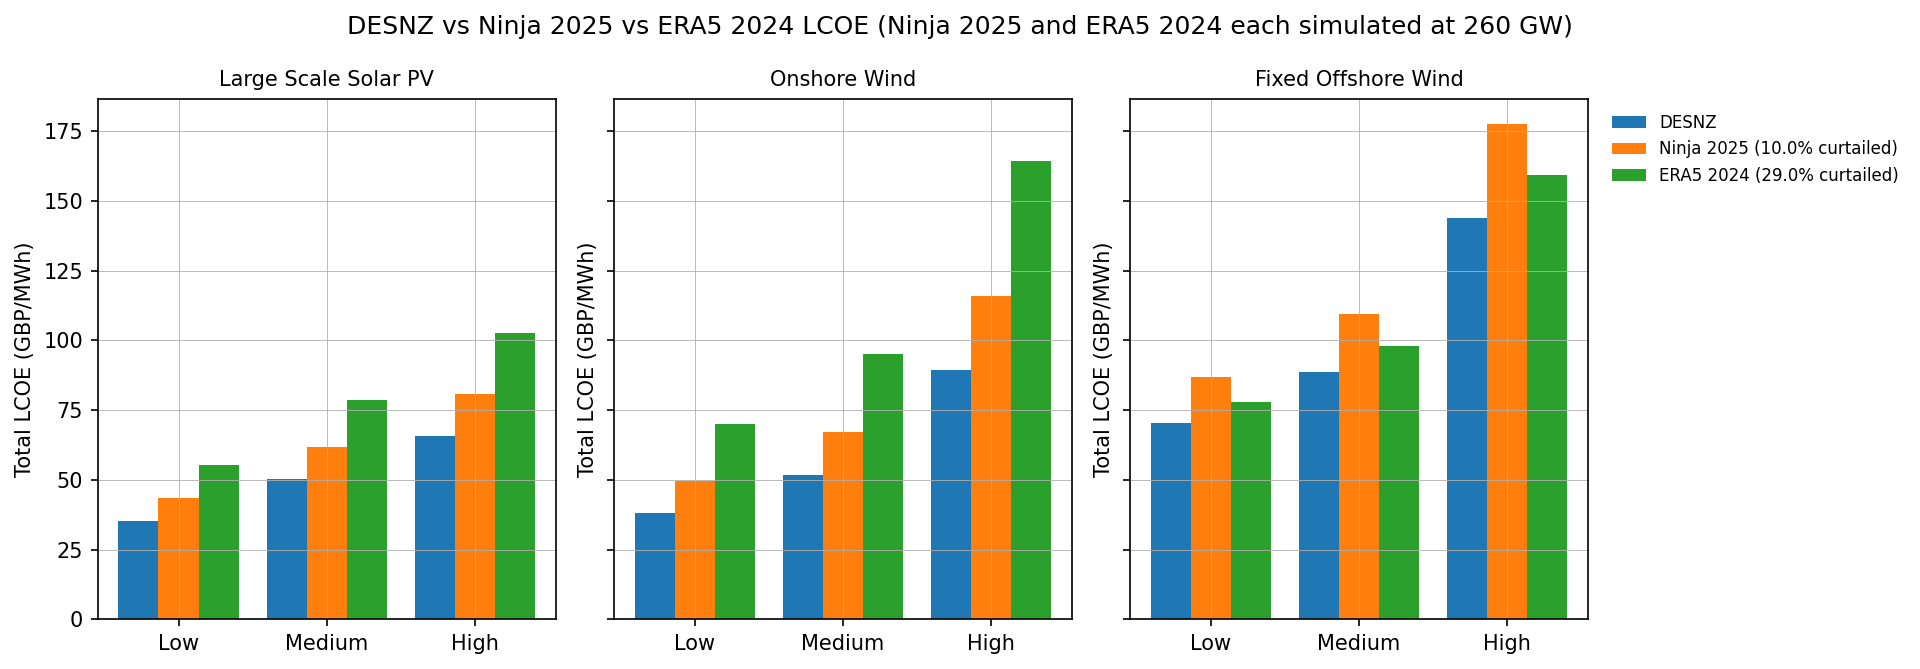

In [10]:
comparison = lcoe_c[lcoe_c["technology"] != "Portfolio (weighted)"]
display(comparison.round(2))

fig, axes = plt.subplots(1, len(CORE_TECHNOLOGIES), figsize=(4.3 * len(CORE_TECHNOLOGIES), 4.5), sharey=True)
x = np.arange(len(SCENARIOS))
width = 0.27

for ax, technology in zip(axes, CORE_TECHNOLOGIES, strict=False):
    subset = comparison[comparison["technology"] == technology].set_index("scenario").loc[SCENARIOS]
    ax.bar(x - width, subset["reference_plant_total"], width, label="DESNZ")
    ax.bar(x, subset["ninja_curtailment_adjusted_total"], width, label=f"Ninja 2025 ({NINJA_CURTAILMENT_FRACTION:.1%} curtailed)")
    ax.bar(x + width, subset["era5_curtailment_adjusted_total"], width, label=f"ERA5 2024 ({curtailment_fraction:.1%} curtailed)")
    ax.set_xticks(x)
    ax.set_xticklabels(SCENARIOS)
    ax.set_title(technology, fontsize=10)
    ax.set_ylabel("Total LCOE (GBP/MWh)")

axes[-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=8)
fig.suptitle(f"DESNZ vs Ninja 2025 vs ERA5 2024 LCOE (Ninja 2025 and ERA5 2024 each simulated at {REN_GW} GW)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "renewable_lcoe_sensitivity_part_c.png", dpi=150, bbox_inches="tight")
plt.show()

C:\Users\Yutong Ren\AppData\Local\Temp\ipykernel_23160\2305710801.py:36: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


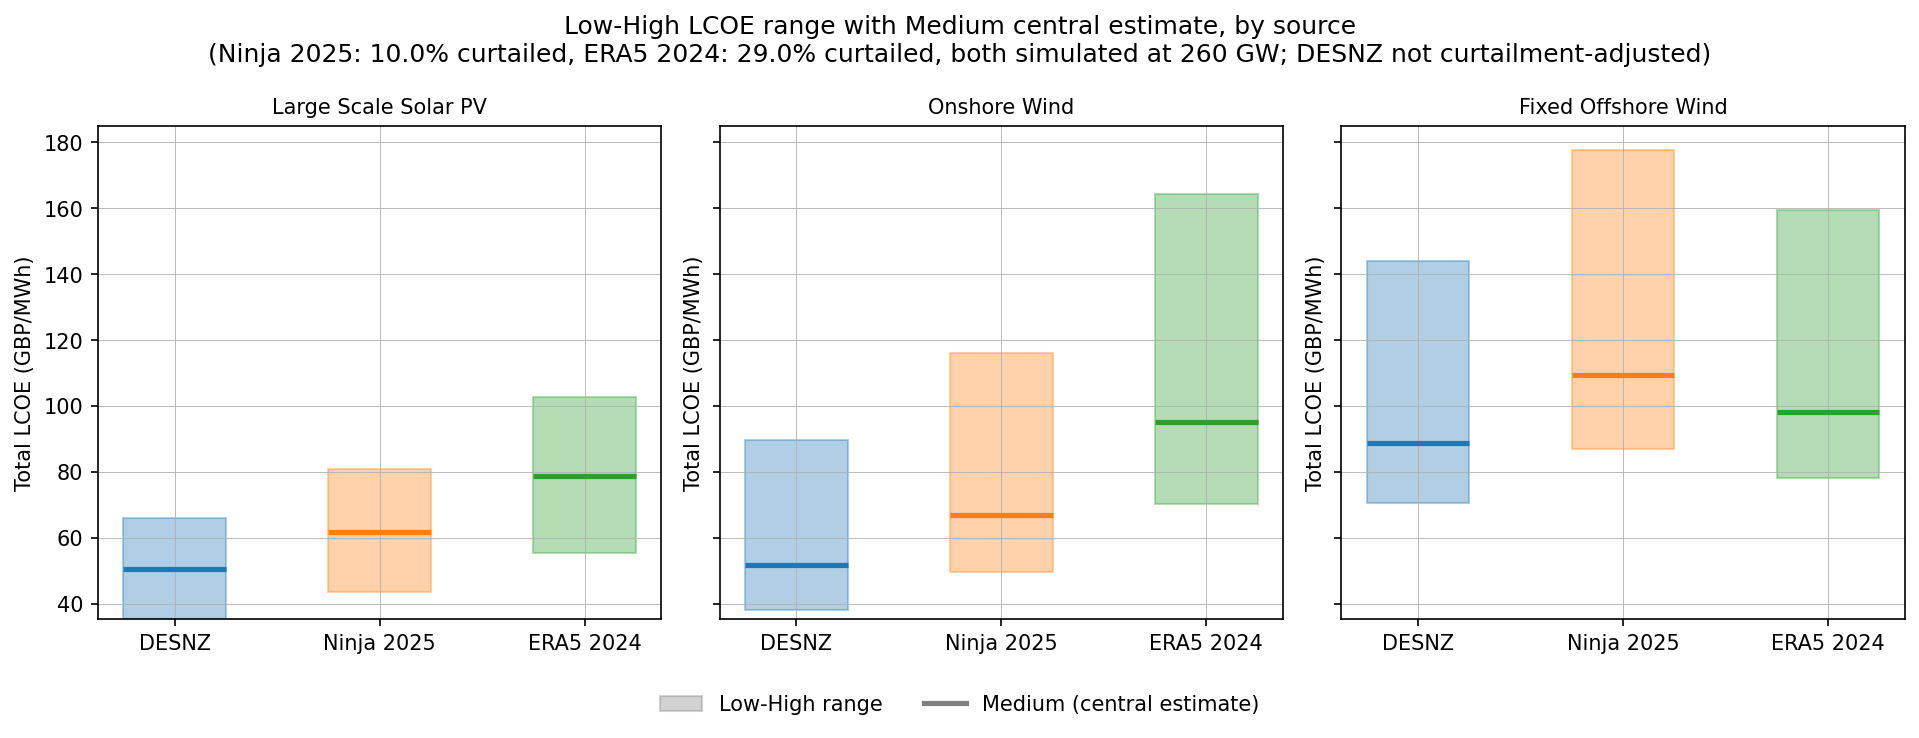

In [11]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Same short labels as Part C's markdown text; curtailment fractions go in the title instead.
sources = [
    ("reference_plant_total", "DESNZ"),
    ("ninja_curtailment_adjusted_total", "Ninja 2025"),
    ("era5_curtailment_adjusted_total", "ERA5 2024"),
]
x = np.arange(len(sources))
width = 0.5

fig, axes = plt.subplots(1, len(CORE_TECHNOLOGIES), figsize=(4.3 * len(CORE_TECHNOLOGIES), 4.5), sharey=True)

for ax, technology in zip(axes, CORE_TECHNOLOGIES, strict=False):
    subset = comparison[comparison["technology"] == technology].set_index("scenario").loc[SCENARIOS]
    for i, (column, label) in enumerate(sources):
        low = subset.loc["Low", column]
        medium = subset.loc["Medium", column]
        high = subset.loc["High", column]
        ax.bar(x[i], high - low, width, bottom=low, color=f"C{i}", alpha=0.35, edgecolor=f"C{i}")
        ax.hlines(medium, x[i] - width / 2, x[i] + width / 2, color=f"C{i}", linewidth=2.5)
    ax.set_xticks(x)
    ax.set_xticklabels([label for _, label in sources])
    ax.set_title(technology, fontsize=10)
    ax.set_ylabel("Total LCOE (GBP/MWh)")

legend_handles = [
    Patch(facecolor="gray", alpha=0.35, edgecolor="gray", label="Low-High range"),
    Line2D([0], [0], color="gray", linewidth=2.5, label="Medium (central estimate)"),
]
fig.suptitle(
    f"Low-High LCOE range with Medium central estimate, by source\n"
    f"(Ninja 2025: {NINJA_CURTAILMENT_FRACTION:.1%} curtailed, ERA5 2024: {curtailment_fraction:.1%} curtailed, both simulated at {REN_GW} GW; DESNZ not curtailment-adjusted)"
)
fig.tight_layout()
fig.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=len(legend_handles), frameon=False)
fig.savefig(OUTPUT_DIR / "renewable_lcoe_sensitivity_part_c_range.png", dpi=150, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "renewable_lcoe_sensitivity_part_c_range.pdf", bbox_inches="tight")
plt.show()

In [12]:
cf_rows = []
for technology in CORE_TECHNOLOGIES:
    cf_rows.append({
        "technology": technology,
        "assumptions_CapacityFactors (legacy static)": MODEL_CAPACITY_FACTOR[technology],
        "ninja_2025_live_PCF": NINJA_POTENTIAL_CF[technology],
        "ninja_2025_ACF_after_curtailment": NINJA_CURTAILED_CF[technology],
        "era5_2024_live_PCF": ERA5_POTENTIAL_CF[technology],
        "era5_2024_ACF_after_curtailment": ERA5_CURTAILED_CF[technology],
    })
print(f"Curtailment used at {REN_GW} GW: Ninja 2025 {NINJA_CURTAILMENT_FRACTION:.1%}, era5_2024 {curtailment_fraction:.1%}")
display(pd.DataFrame(cf_rows).round(3))

Curtailment used at 260 GW: Ninja 2025 10.0%, era5_2024 29.0%


,technology,assumptions_CapacityFactors (legacy static),ninja_2025_live_PCF,ninja_2025_ACF_after_curtailment,era5_2024_live_PCF,era5_2024_ACF_after_curtailment
0,Large Scale Solar PV,0.108,0.109,0.098,0.108,0.077
1,Onshore Wind,0.293,0.317,0.286,0.284,0.202
2,Fixed Offshore Wind,0.383,0.450,0.405,0.636,0.451


**Why ERA5 2024's LCOE differs from Ninja 2025's for Fixed Offshore Wind**:
the two capacity-factor sources still disagree for offshore wind -- the live
`ninja_2025` series gives a potential capacity factor of ~0.45, against ~0.64
for `era5_2024` (see the table above). So ERA5 2024's lower LCOE for offshore
wind isn't curtailment helping -- it's that even after curtailment, the
ERA5 2024-implied capacity factor is still well above the Ninja 2025 one.
Both are simulated at the same installed capacity, so this gap comes from the
weather series (capacity factors and how well supply matches demand), not
from system size.

Two further data-source notes, both pre-existing in the repo rather than
artefacts of this notebook:

- `src/assumptions.py`'s legacy static constant `OffshoreWind = 0.383` carries
  the comment `# 61% according to Department for Net Zero`, but the DESNZ
  reference-plant load factor actually used in `src/lcoe.py`
  (`RENEWABLES_2050_PARAMS`) is **0.50**. Worth confirming which is right
  against Annex A.
- It's worth resolving which offshore wind capacity-factor source the model
  should treat as authoritative going forward (`era5_2024` is what
  `PowerSystem` and the rest of `nbs/` already default to).

**Caveat** (from `src/curtailment_lcoe.py`'s module docstring): this model's
simulation only tracks curtailment on the *combined* renewable supply, not
per technology, so each source's curtailment rate above is applied uniformly
(pro-rata) to all three technologies -- it is not a per-technology curtailment
estimate. The Ninja 2025 and ERA5 2024 rates come from separate simulations
(own weather), so they are not forced to be equal.

## Part D -- Broader Annex A sweep (extra technologies + commissioning years)

Extends beyond the 3 technologies/2050-only scope above to every DESNZ
commissioning year (2030-2050), still across Low/Medium/High, and adds two
further renewable/low-carbon technologies from Annex A: **Tidal Stream
Energy** and **Deep Granite Geothermal**.

**Floating Offshore Wind is deliberately excluded**: Annex A does not publish
a usable "Average load factor" for it -- the 2030 row is a footnote reference
(`"See footnote11"`) and 2035-2050 are `null` -- so `calculate_lcoe` cannot be
run for it without inventing a capacity-factor assumption not actually in the
source data.

**This part does not include curtailment adjustment**: `curtailment_lcoe.py`
only supports the three core technologies at 2050 commissioning
(`renewables_2050_lcoe` has no `year` parameter, and Tidal Stream/Geothermal
aren't in its technology/capacity-ratio maps) -- extending that would require
new capacity-factor and capacity-ratio data for these technologies, which is
out of scope here.

In [13]:
EXTENDED_TECHNOLOGIES = [*CORE_TECHNOLOGIES, "Tidal Stream Energy", "Deep Granite Geothermal"]
YEARS = ["2030", "2035", "2040", "2045", "2050"]

annex_a = load_technical_assumptions()

rows_d = []
for technology in EXTENDED_TECHNOLOGIES:
    for year in YEARS:
        for scenario in SCENARIOS:
            params = annex_a[technology][year]
            total = calculate_lcoe(params, scenario)["total"].to(U.GBP / U.MWh).magnitude
            rows_d.append({"technology": technology, "year": int(year), "scenario": scenario, "total": total})

lcoe_d = pd.DataFrame(rows_d)
display(lcoe_d.pivot_table(index=["technology", "year"], columns="scenario", values="total").round(2))

scenario                        High     Low  Medium
technology              year                        
Deep Granite Geothermal 2030  904.96  201.46  339.97
                        2035  216.83   89.66  128.62
                        2040  212.44   88.42  125.74
                        2045  208.04   87.18  124.30
                        2050  205.85   87.18  122.86
Fixed Offshore Wind     2030  174.44   79.82  102.72
                        2035  163.15   75.51   97.50
                        2040  153.64   71.31   92.32
                        2045  148.70   70.72   89.24
                        2050  143.85   70.49   88.64
Large Scale Solar PV    2030   76.08   43.01   58.93
                        2035   75.80   35.92   50.94
                        2040   66.17   35.73   50.75
                        2045   65.98   35.54   50.56
                        2050   65.88   35.45   50.46
Onshore Wind            2030  100.75   42.78   59.81
                        2035   94.25   41.16   55.08
                        2040   93.94   40.85   54.77
                        2045   93.02   38.41   54.59
                        2050   89.55   38.26   51.78
Tidal Stream Energy     2030  346.85  236.98  285.45
                        2035  221.04  149.33  168.50
                        2040  177.21  125.19  138.93
                        2045  160.02  113.65  125.92
                        2050  144.75  102.35  114.14

C:\Users\Yutong Ren\AppData\Local\Temp\ipykernel_23160\4230702538.py:14: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


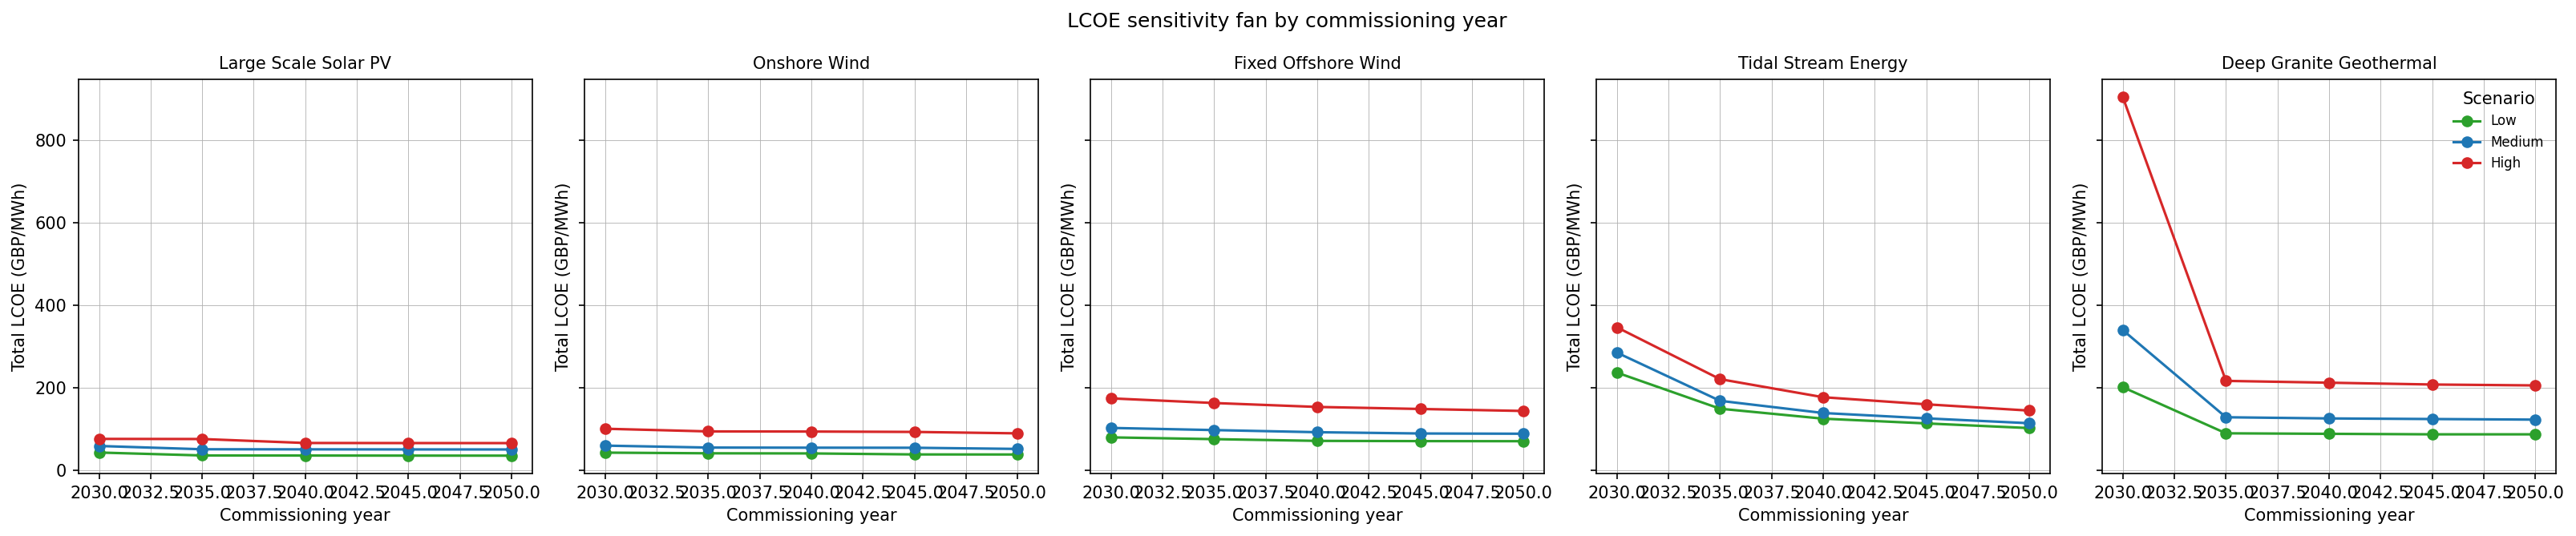

In [14]:
fig, axes = plt.subplots(1, len(EXTENDED_TECHNOLOGIES), figsize=(4.3 * len(EXTENDED_TECHNOLOGIES), 4.5), sharey=True)

for ax, technology in zip(axes, EXTENDED_TECHNOLOGIES, strict=False):
    subset = lcoe_d[lcoe_d["technology"] == technology]
    for scenario in SCENARIOS:
        series = subset[subset["scenario"] == scenario].sort_values("year")
        ax.plot(series["year"], series["total"], marker="o", label=scenario, color=SCENARIO_COLORS[scenario])
    ax.set_title(technology, fontsize=10)
    ax.set_xlabel("Commissioning year")
    ax.set_ylabel("Total LCOE (GBP/MWh)")

axes[-1].legend(title="Scenario", frameon=False, fontsize=8)
fig.suptitle("LCOE sensitivity fan by commissioning year")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "renewable_lcoe_sensitivity_part_d.png", dpi=150, bbox_inches="tight")
plt.show()

## Part E -- E-DAC equipment-only LCOR sensitivity, Low / Medium / High

This model's E-DAC costs (`src.assumptions.EDAC`, `src.costs.edac_equipment_costs`)
are **equipment-only** LCOR: annualised CAPEX + fixed OPEX, excluding
electricity, labour, sorbent, transport and CO2 storage costs (see
`edac_equipment_costs`'s own docstring). A Wright's-law learning curve scales
the reference-plant CAPEX/OPEX down using an assumed 2050 global cumulative
E-DAC deployment (`A.EDAC.CumulativeDeployment = 9.0 Mt/yr`) -- a figure the
code itself marks `"team assumption, TBC"`, with no literature source.

This section builds a Low/Medium/High range by varying that deployment
assumption (the genuinely uncertain lever) and the discount-rate scenario
(`CentralDiscountRate`/`SensitivityDiscountRate`, both already in
`assumptions.py`), reusing the same Wright's-law formula and the
parameterised `edac_lcor` helper pattern already used in
`nbs/edac_learning_effect_comparison.ipynb`:

- **Low (optimistic 2050)**: 2050 cumulative deployment = 980 MtCO2/yr, the
  IEA Net Zero Emissions (NZE) scenario's DAC trajectory (IEA, *Net Zero by
  2050: A Roadmap for the Global Energy Sector*, 2021; reiterated in IEA's
  *Direct Air Capture* 2022/2024 reports) -- roughly 109x the repo's
  placeholder deployment -- at `CentralDiscountRate` (5%).
- **Medium (repo's current central case, unchanged)**: the repo's existing
  `A.EDAC.CumulativeDeployment` (9.0 Mt/yr, unsourced placeholder) at
  `CentralDiscountRate` -- i.e. exactly today's `Learned*` constants.
- **High (pessimistic / first-of-a-kind)**: no learning applied at all
  (deployment ratio = 1, the raw reference-plant CAPEX/OPEX) at
  `SensitivityDiscountRate` (10%) -- the same "No-learning baseline --
  Sensitivity (10%)" case already computed in
  `edac_learning_effect_comparison.ipynb`.

**Literature support for the learning rate**: Fasihi, Efimova & Breyer (2019,
*Journal of Cleaner Production*) report DAC CAPEX learning rates of
**10-15%** -- the repo's 14% figure sits squarely inside this range. No
DAC-specific published OPEX learning rate was found; the repo's 2.5% OPEX
figure is a plausible but unverified placeholder (OPEX in the literature is
usually energy-price-driven rather than learning-curve-driven).

**Open item**: the repo's own citation for the reference-plant CAPEX,
"Leonzio & Shah (2025)", could not be independently verified in this
research pass -- the closest confirmed match (Leonzio & Shah, *RSC
Sustainability*, 2025) covers electrochemical DAC, not solid-sorbent E-DAC,
so it is likely a different paper. Worth the team confirming the DOI.

In [15]:
from src.utils import annualised_cost

EDAC_REFERENCE_INSTALLED_POWER = 1 * U.GW  # arbitrary: LCOR is independent of installed power
                                            # (CAPEX, OPEX and removals all scale with it linearly)


def edac_nameplate_removals(installed_power):
    """Full-load annual CO2 removal capacity implied by an installed E-DAC power."""
    nameplate_energy = (installed_power * A.HoursPerYear).to(U.TWh)
    return (nameplate_energy / A.DAC.EnergyCost.MediumTWhPerMtCO2).to(U.t)


def edac_lcor(capex_per_capacity, opex_per_capacity, capacity_factor, discount_rate, installed_power=EDAC_REFERENCE_INSTALLED_POWER):
    """Equipment-only LCOR for arbitrary CAPEX/OPEX-per-capacity inputs.

    Mirrors src.costs.edac_equipment_costs's formula exactly, but takes the
    CAPEX/OPEX-per-capacity as parameters so Low/Medium/High cases can be
    computed without modifying src/ (same pattern as
    nbs/edac_learning_effect_comparison.ipynb's edac_lcor()).
    """
    removals = edac_nameplate_removals(installed_power)
    actual_removals = removals * capacity_factor
    total_capex = (removals * capex_per_capacity).to(U.GBP)
    annualised_capex = annualised_cost(total_capex, 0 * U.GBP, A.EDAC.Lifetime, discount_rate)
    fixed_opex = (removals * opex_per_capacity).to(U.GBP)
    annual_cost = annualised_capex + fixed_opex
    if actual_removals.magnitude <= 0:
        return float("inf")
    return (annual_cost / actual_removals).to(U.GBP / U.t).magnitude


def learned_edac_cost(cumulative_deployment):
    """Reproduces A.EDAC's Wright's-law formula for an arbitrary 2050 cumulative deployment."""
    deployment_ratio = (cumulative_deployment / A.EDAC.ReferenceCumulativeDeployment).to(U.dimensionless).magnitude
    learned_capex = A.EDAC.CapexPerAnnualCaptureCapacity * deployment_ratio**A.EDAC.CapexLearningExponent
    learned_opex = A.EDAC.CapexPerAnnualCaptureCapacity * A.EDAC.FixedOpexFraction * deployment_ratio**A.EDAC.OpexLearningExponent
    return learned_capex, learned_opex


# Correctness check: learned_edac_cost() at the repo's own deployment assumption
# must reproduce A.EDAC.Learned* exactly (same formula, just re-parameterised).
_check_capex, _check_opex = learned_edac_cost(A.EDAC.CumulativeDeployment)
assert abs(_check_capex.to(U.GBP / U.t).magnitude - A.EDAC.LearnedCapexPerAnnualCaptureCapacity.to(U.GBP / U.t).magnitude) < 1e-6
assert abs(_check_opex.to(U.GBP / U.t).magnitude - A.EDAC.LearnedFixedOpexPerAnnualCaptureCapacity.to(U.GBP / U.t).magnitude) < 1e-6
print("Correctness check passed: learned_edac_cost() matches A.EDAC.Learned* at the repo's own deployment assumption.")

Correctness check passed: learned_edac_cost() matches A.EDAC.Learned* at the repo's own deployment assumption.


In [16]:
IEA_NZE_2050_DAC_DEPLOYMENT = 980e6 * U.t  # IEA (2021) Net Zero by 2050; reiterated in IEA Direct Air Capture 2022/2024

low_capex, low_opex = learned_edac_cost(IEA_NZE_2050_DAC_DEPLOYMENT)
edac_scenarios = {
    "Low": (low_capex, low_opex, A.EDAC.CentralDiscountRate),
    "Medium": (A.EDAC.LearnedCapexPerAnnualCaptureCapacity, A.EDAC.LearnedFixedOpexPerAnnualCaptureCapacity, A.EDAC.CentralDiscountRate),
    "High": (A.EDAC.CapexPerAnnualCaptureCapacity, A.EDAC.CapexPerAnnualCaptureCapacity * A.EDAC.FixedOpexFraction, A.EDAC.SensitivityDiscountRate),
}

edac_capacity_factor = simulation_results["dac_capacity_factor"]  # reuse Part C's representative simulation -- no second run needed

rows_e = []
for scenario in SCENARIOS:
    capex, opex, discount_rate = edac_scenarios[scenario]
    lcor = edac_lcor(capex, opex, edac_capacity_factor, discount_rate)
    rows_e.append({
        "scenario": scenario,
        "capex_gbp_per_t_capacity": capex.to(U.GBP / U.t).magnitude,
        "opex_gbp_per_t_capacity": opex.to(U.GBP / U.t).magnitude,
        "discount_rate": discount_rate,
        "equipment_only_lcor_gbp_per_t": lcor,
    })

lcoe_e = pd.DataFrame(rows_e)
print(f"Representative E-DAC capacity factor (reused from Part C's simulation): {edac_capacity_factor:.1%}")
display(lcoe_e.round(2))

Representative E-DAC capacity factor (reused from Part C's simulation): 72.7%


,scenario,capex_gbp_per_t_capacity,opex_gbp_per_t_capacity,discount_rate,equipment_only_lcor_gbp_per_t
0,Low,57.46,8.75,0.05,18.36
1,Medium,159.45,10.38,0.05,31.86
2,High,503.57,12.59,0.10,98.62


C:\Users\Yutong Ren\AppData\Local\Temp\ipykernel_23160\3499519124.py:6: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


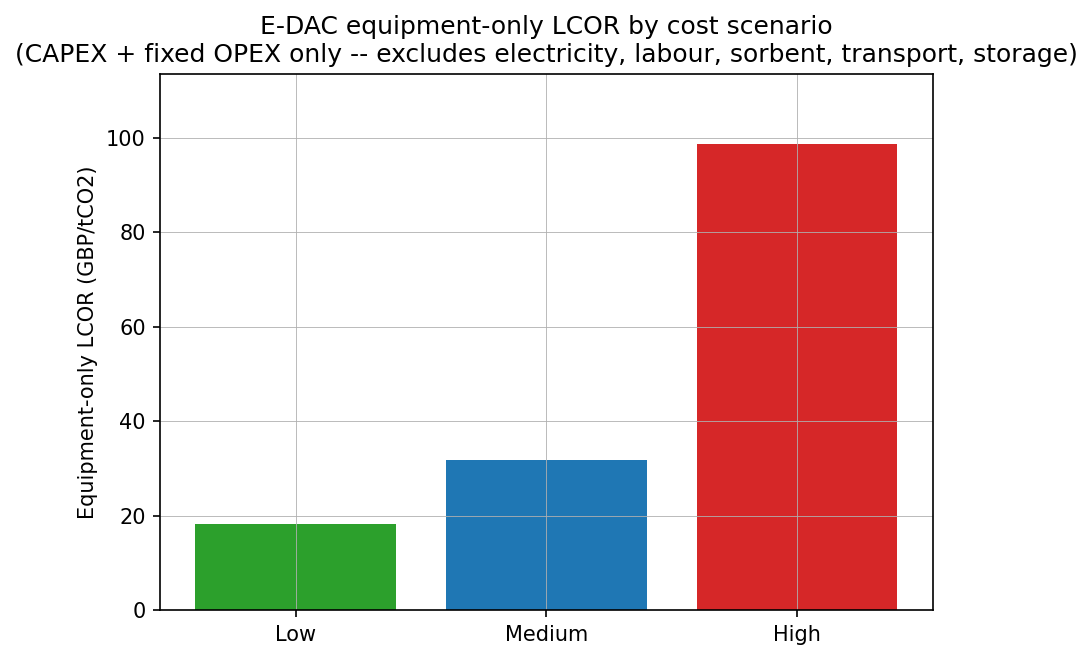

In [17]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Combine the Low, Medium, and High scenarios into one range bar.
subset = lcoe_e.set_index("scenario").loc[["Low", "Medium", "High"]]

low = subset.loc["Low", "equipment_only_lcor_gbp_per_t"]
medium = subset.loc["Medium", "equipment_only_lcor_gbp_per_t"]
high = subset.loc["High", "equipment_only_lcor_gbp_per_t"]

x = 0
width = 0.5
bar_color = SCENARIO_COLORS["Medium"]

fig, ax = plt.subplots(figsize=(4.5, 4.5))

# Floating bar represents the Low-High range.
ax.bar(
    x,
    high - low,
    width,
    bottom=low,
    color=bar_color,
    alpha=0.35,
    edgecolor=bar_color,
)

# Horizontal line represents the Medium estimate.
ax.hlines(
    medium,
    x - width / 2,
    x + width / 2,
    color=bar_color,
    linewidth=2.5,
)

ax.set_xticks([x])
ax.set_xticklabels(["E-DAC"])
ax.set_xlim(-0.6, 0.6)
ax.set_ylabel("Equipment-only LCOR (GBP/tCO2)")
ax.set_ylim(0, high * 1.15)

ax.set_title(
    "Low-High E-DAC  LCOR range\n"
    "with Medium central estimate\n"
)

legend_handles = [
    Patch(
        facecolor=bar_color,
        alpha=0.35,
        edgecolor=bar_color,
        label="Low-High range",
    ),
    Line2D(
        [0],
        [0],
        color=bar_color,
        linewidth=2.5,
        label="Medium (central estimate)",
    ),
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.0),
    ncol=2,
    frameon=False,
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "renewable_lcoe_sensitivity_part_e_edac_range.png",
    dpi=150,
    bbox_inches="tight",
)
fig.savefig(
    OUTPUT_DIR / "renewable_lcoe_sensitivity_part_e_edac_range.pdf",
    bbox_inches="tight",
)

plt.show()

In [18]:
lcor_table = lcoe_e.set_index("scenario")[["capex_gbp_per_t_capacity", "opex_gbp_per_t_capacity", "discount_rate", "equipment_only_lcor_gbp_per_t"]]
display(lcor_table.round(2))

,capex_gbp_per_t_capacity,opex_gbp_per_t_capacity,discount_rate,equipment_only_lcor_gbp_per_t
scenario,,,,
Low,57.46,8.75,0.05,18.36
Medium,159.45,10.38,0.05,31.86
High,503.57,12.59,0.10,98.62


In [19]:
literature_full_lcod = pd.DataFrame([
    {"source": "IEA, Direct Air Capture 2024", "year": 2024, "figure": "Solid-sorbent DAC full LCOD up to $540/tCO2 (current)"},
    {"source": "Fasihi, Efimova & Breyer (2019), J. Cleaner Production", "year": 2019, "figure": "2050 full LCOD $20-130/tCO2 under 10-15% learning"},
    {"source": "Solid-sorbent DAC TEA, ScienceDirect", "year": 2025, "figure": "Full LCOD(net) $148-623/tCO2 (2025) falling to $112-523/tCO2 (2050)"},
    {"source": "McQueen et al., review", "year": 2021, "figure": "Literature spread $20-1,000/tCO2; current gross costs mostly $600-1,000/tCO2"},
])
display(literature_full_lcod)

,source,year,figure
0,"IEA, Direct Air Capture 2024",2024,Solid-sorbent DAC full LCOD up to $540/tCO2 (c...
1,"Fasihi, Efimova & Breyer (2019), J. Cleaner Pr...",2019,2050 full LCOD $20-130/tCO2 under 10-15% learning
2,"Solid-sorbent DAC TEA, ScienceDirect",2025,Full LCOD(net) $148-623/tCO2 (2025) falling to...
3,"McQueen et al., review",2021,"Literature spread $20-1,000/tCO2; current gros..."


**Not directly comparable**: the figures above are **full LCOD** (equipment +
electricity + sorbent + transport + CO2 storage), while this notebook's
Low/Medium/High bars are **equipment-only**. The equipment-only figure is
expected to sit below these full-LCOD numbers since it omits several major
cost components -- shown here only as literature context, not plotted
alongside the equipment-only bars.

## Summary

- Run the notebook and inspect the tables/charts above for the current
  Low/Medium/High spread per technology; figures will vary as Annex A
  assumptions are updated, so this section intentionally does not hardcode
  numbers.
- Part A's stacked breakdown shows which cost component drives most of the
  Low-to-High movement for each technology, now on an era5_2024
  curtailment-adjusted basis (matching the capacity-factor source used
  everywhere else in `nbs/`).
- Part C's three-way comparison (DESNZ, Ninja 2025, ERA5 2024) makes the
  Ninja 2025-vs-ERA5 2024 capacity-factor discrepancy visible directly in the
  LCOE numbers, which is especially large for Fixed Offshore Wind (see Part
  C's note). Ninja 2025 and ERA5 2024 each use the curtailment fraction
  of their own simulation, both run at the same installed capacity (`REN_GW`,
  the smallest size at which Ninja 2025's weaker offshore wind can still meet
  demand).
- Part D's fan charts show whether the Low/High range narrows or widens over
  the 2030-2050 commissioning horizon, and add Tidal Stream Energy and Deep
  Granite Geothermal to the picture (Floating Offshore Wind is excluded --
  Annex A publishes no usable load factor for it) -- but without curtailment
  adjustment (see Part D's caveat).
- Part E builds a literature-informed Low/Medium/High for E-DAC's
  equipment-only LCOR by varying the genuinely uncertain 2050 global
  deployment assumption (IEA's NZE ~980 Mt/yr vs the repo's unsourced 9 Mt/yr
  placeholder) and the discount-rate scenario; its supporting 14% CAPEX
  learning rate is well within Fasihi et al. (2019)'s literature range, but
  the repo's reference-plant CAPEX citation ("Leonzio & Shah (2025)") could
  not be independently verified and is flagged as an open item. The
  equipment-only figures are intentionally lower than literature's full-LCOD
  range, since they exclude electricity, sorbent, transport and storage
  costs.